# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 3 - Module 3
### **Practical 7: Convergence Analysis of a Genetic Algorithm**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module III: Genetic Algorithms and Evolutionary Computing |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To study the convergence of a Genetic Algorithm by observing changes in fitness values over multiple generations using Python.

### 2. Theory: GA Convergence

Convergence analysis tracks **Best Fitness**, **Average Fitness**, and **Worst Fitness** across generations:
- Rapid initial improvement indicates **exploration**.
- Narrowing gap between average and best fitness indicates **exploitation** and population convergence.
- If diversity drops too early, the GA may suffer from **premature convergence**.

### 3. Step 1: Running GA and Recording Generation Statistics

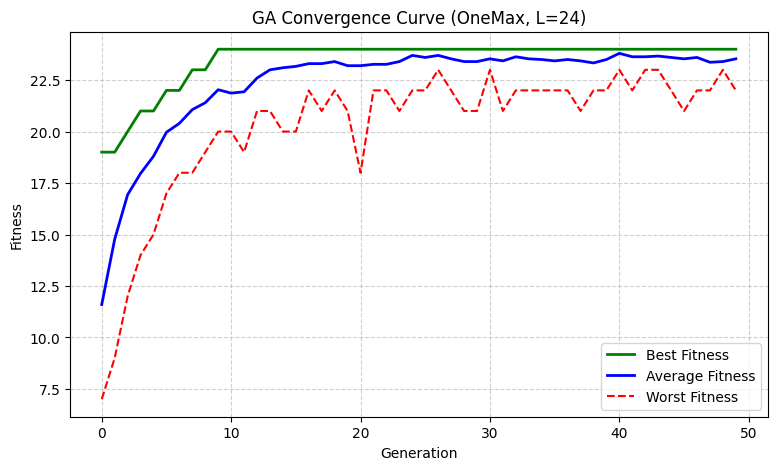

Initial Best: 19, Final Best: 24, Final Avg: 23.53


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)

def ga_with_stats(pop_size=30, chrom_len=24, generations=50, pc=0.8, pm=0.02):
    pop = np.random.randint(0, 2, size=(pop_size, chrom_len))
    best_hist, avg_hist, worst_hist = [], [], []

    for _ in range(generations):
        fit = np.sum(pop, axis=1)
        best_hist.append(np.max(fit))
        avg_hist.append(np.mean(fit))
        worst_hist.append(np.min(fit))

        new_pop = [pop[np.argmax(fit)].copy()]
        while len(new_pop) < pop_size:
            c1 = np.random.choice(pop_size, 3, replace=False)
            p1 = pop[c1[np.argmax(fit[c1])]]
            c2 = np.random.choice(pop_size, 3, replace=False)
            p2 = pop[c2[np.argmax(fit[c2])]]

            if np.random.rand() < pc:
                pt = np.random.randint(1, chrom_len)
                o1 = np.concatenate([p1[:pt], p2[pt:]])
                o2 = np.concatenate([p2[:pt], p1[pt:]])
            else:
                o1, o2 = p1.copy(), p2.copy()

            for o in (o1, o2):
                mask = np.random.rand(chrom_len) < pm
                o[mask] = 1 - o[mask]
                if len(new_pop) < pop_size:
                    new_pop.append(o)
        pop = np.array(new_pop)

    return best_hist, avg_hist, worst_hist

best_h, avg_h, worst_h = ga_with_stats()

plt.figure(figsize=(9, 5))
plt.plot(best_h, label='Best Fitness', linewidth=2, color='green')
plt.plot(avg_h, label='Average Fitness', linewidth=2, color='blue')
plt.plot(worst_h, label='Worst Fitness', linewidth=1.5, linestyle='--', color='red')
plt.title("GA Convergence Curve (OneMax, L=24)")
plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"Initial Best: {best_h[0]}, Final Best: {best_h[-1]}, Final Avg: {avg_h[-1]:.2f}")

### 4. Conclusion
By plotting Best, Average, and Worst fitness over 50 generations, we observed how the population converges toward the global optimum.